# Field tracing: rays and waves in one chain

An optical system is a sequence of components (lenses, plates, apertures,
beam splitters) with free space between them. There are two classic ways to
simulate light going through it:

* **Ray tracing** follows rays through the real surfaces. It is fast and
  handles thick, strongly curved lenses easily, but rays know nothing about
  diffraction: they fail at a focus, behind an edge or a small particle,
  and in interference patterns that depend on small path differences.
* **Wave propagation** samples the complex field on a grid and propagates
  it with Fourier transforms. That includes diffraction, but a single grid
  must resolve the finest detail over the largest beam at every plane, and
  strongly curved wavefronts or long distances make it explode.

**Field tracing** (F. Wyrowski and M. Kuhn, J. Mod. Opt. 58, 449, 2011)
combines both. It always carries the *field*: the transverse electric
field $E_x, E_y$ on a grid, with the phase. Each step of the system, though,
is modelled with whatever method is accurate enough there and cheapest:
rays through the glass of a lens, a rigorous plane wave decomposition just
behind an aperture, a far-field formula a long way behind it. Every step
is an *operator* that takes a field and returns a field, and the whole
system is the product of these operators, applied in order:

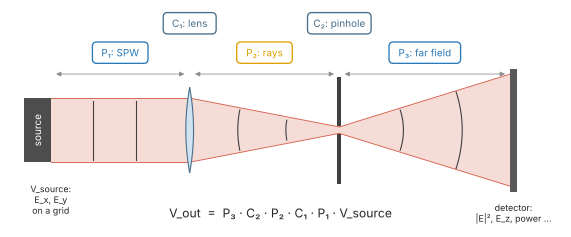

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
from scipy.special import erf, j0

from pyoptics import fieldtrace as ft
from pyoptics import sketch
from pyoptics.raytrace import System, Surface
from pyoptics.analytical import sphere_field
from pyoptics.propagators import rayleigh_sommerfeld_I_TF

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "0.45"
t_start = time.time()

fig, ax = plt.subplots(figsize=(12, 3.6))
sketch.field_tracing_chain(ax)
plt.show()

The $P$ are the free-space steps, the $C$ the components. In
`pyoptics.fieldtrace` this product is literally a list of steps:

```python
chain = ft.Chain([ft.ThinLens(100.0), ft.Propagate(100.0), ft.Detector("focus")])
result = chain.run(source)          # result["focus"].irradiance, result.report()
```

The model assumes that light goes through the components one after the
other, each lit only by the one before it (no light bouncing back and forth
between them). That covers most lens systems and interferometers.

## 1. The field and its phase

A grid must sample the phase of the field finely enough: neighbouring
samples may differ by at most π. A converging or diverging beam has a
curved wavefront, $\psi(x, y) \approx k (x^2 + y^2)/(2R)$, whose phase
changes faster and faster towards the edge of the beam. A beam of 10 mm
with a radius of curvature of 100 mm at 633 nm needs thousands of samples
per axis for that phase alone, although the amplitude is smooth.

A `ft.Field` therefore stores the field as a smooth sampled amplitude times
a quadratic phase that is kept as a formula,

$$E_{x,y}(x, y) = A_{x,y}(x, y)\,\exp\!\big(i(\alpha_x x^2 + \alpha_y y^2 + \beta_x x + \beta_y y + \gamma)\big),$$

so that a lens only changes $\alpha$, and the grid only has to resolve
what is left. The propagation methods below handle the formula
analytically (the "semi-analytical Fourier transform").

In [2]:
wl = 632.8e-6                                        # mm
x = np.linspace(-6.25, 6.25, 64)
X, Y = np.meshgrid(x, x)
aperture = np.exp(-(np.hypot(X, Y)/5.0)**20)         # 10 mm aperture with soft edges
R = -100.0                                           # converging, 100 mm to the focus
k = 2*np.pi/wl
# the phase k r**2/(2R) changes fastest at the edge of the beam (r = 5 mm):
# by k*5/|R| per mm, which must stay below pi per sample
dx_needed = np.pi/(k*5.0/abs(R))
print("samples per axis the sampled phase needs: {:.0f} (spacing {:.1f} µm)".format(
    (x[-1] - x[0])/dx_needed, 1E3*dx_needed))
field = ft.Field(aperture, x, x, wl, alpha=(k/(2*R), k/(2*R)))
print("samples per axis with the quadratic phase as a formula: {}".format(field.shape[1]))

samples per axis the sampled phase needs: 1975 (spacing 6.3 µm)
samples per axis with the quadratic phase as a formula: 64


## 2. Four ways to propagate through free space

A free-space step can be computed in several ways, with very different
cost and range of validity:

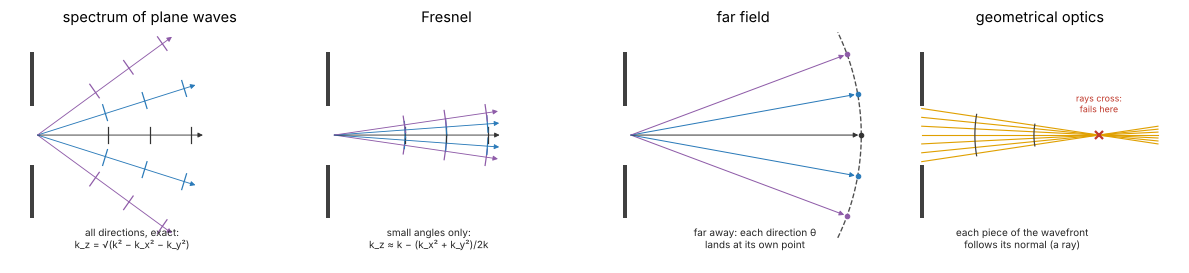

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, m in zip(axes, ("spw", "fresnel", "farfield", "geometric")):
    sketch.propagation_operators(ax, m)
plt.tight_layout(); plt.show()

* **Spectrum of plane waves (SPW, `"spw"`).** The field is decomposed into
  plane waves by a Fourier transform; each plane wave travels in its own
  direction and only picks up the phase $k_z z$ with
  $k_z = \sqrt{k^2 - k_x^2 - k_y^2}$; an inverse transform gives the new
  field. This is the exact solution of the wave equation in free space and
  serves as the reference. Its weakness: the output lives on the input's
  grid, so a beam that spreads a lot needs a large, padded window.
* **Fresnel (`"fresnel"`, `"fresnel_ft"`).** The same for small angles,
  with $k_z$ replaced by its parabolic approximation. The parabola can be
  carried analytically, which makes it cheap. In the single-transform form
  (`"fresnel_ft"`) the output grid is chosen freely, so a small field may
  spread onto a large window at no extra cost.
* **Far field (`"farfield"`).** Far enough away, every direction of the
  plane wave spectrum arrives at its own point of the observation plane:
  the field there is the spectrum, read off at the angle of each point,
  times a spherical wave. One transform, no padding, but only valid at
  large distances (Fresnel number $a^2/\lambda z \ll 1$ for an aperture
  of radius $a$).
* **Geometrical optics (`"geometric"`).** Each small piece of the
  wavefront travels along its normal, a ray, carrying its energy; the
  field is rebuilt from where the rays arrive. It needs no sampling of the
  diffraction at all, and fails where rays cross (a focus, a caustic).

## 3. Letting the chain choose

`Propagate(z)` picks the method automatically for every step. It cuts the
field along x and y (two 1D fields, cheap to propagate) and, for every
method, refines the sampling until its result stops changing. The number of
samples it then needs is the method's **effort**. The converged SPW result
is the reference, and the relative difference of a method's result from it
is that method's **error**. The cheapest method whose error is below the
tolerance (default 1 %) is used for the full 2D field; the decision is
logged.

Four test cases at 633 nm, the ones Wyrowski and Kuhn use to explain the
idea:

* a circular aperture of 50 µm radius with soft edges, observed 1 mm and
  10 mm behind it,
* a 5 µm aperture observed 10 mm behind it: the light spreads over a huge
  area compared with the aperture,
* a converging spherical wave behind a 10 mm aperture, 50 mm before its
  focus.

case                           choice                     spw            fresnel         fresnel_ft           farfield          geometric


50 µm aperture, z = 1 mm       spw              0e+00 / 16384      6e-05 / 16384      6e-04 / 16384       1e+00 / 4096      2e-01 / 16129
50 µm aperture, z = 10 mm      fresnel_ft       0e+00 / 16384      5e-04 / 16384       1e-03 / 4096       5e-01 / 4096      4e-01 / 16129


5 µm aperture, z = 10 mm       farfield     0e+00 / 260176900      3e-01 / 16384       3e-01 / 4096   5e-03 / 16777216      1e+00 / 16129
10 mm sphere R = -100, z = 50  spw               0e+00 / 9604       1e-01 / 9604       1e-01 / 4096       1e+00 / 4096      7e-03 / 16129

(error / effort = samples N_x N_y; tolerance 1e-2)


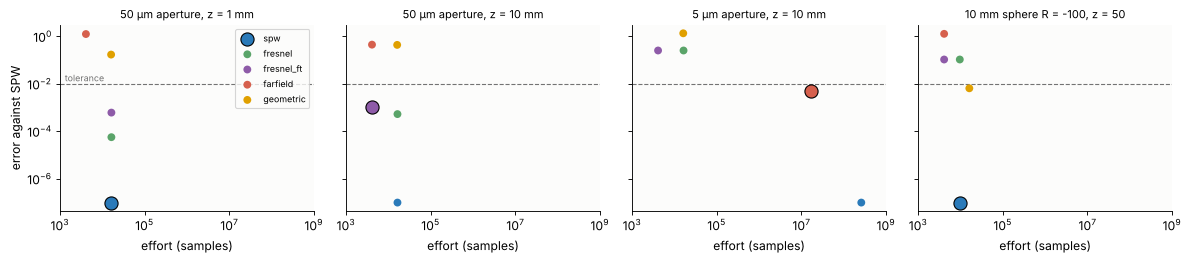

In [4]:
def aperture_field(radius, R=np.inf, order=10, N=64):
    # super-Gaussian aperture of the given radius on a window of 1.25 radii
    x = np.linspace(-1.25*radius, 1.25*radius, N)
    X, Y = np.meshgrid(x, x)
    alpha = 0.0 if np.isinf(R) else np.pi/(wl*R)
    u = np.exp(-(np.hypot(X, Y)/radius)**order)
    return ft.Field(u, x, x, wl, alpha=(alpha, alpha))

rows = [("50 µm aperture, z = 1 mm", aperture_field(0.05), 1.0),
        ("50 µm aperture, z = 10 mm", aperture_field(0.05), 10.0),
        ("5 µm aperture, z = 10 mm", aperture_field(0.005), 10.0),
        ("10 mm sphere R = -100, z = 50", aperture_field(5.0, R=-100.0, order=20), 50.0)]
tables = []
print("{:30s} {:11s}  ".format("case", "choice") + "  ".join("{:>17s}".format(m) for m in ft.METHODS))
for name, f, z in rows:
    choice, t = ft.estimate_propagation(f, z)
    tables.append((name, choice, t))
    cells = []
    for m in ft.METHODS:
        e, n = t[m]["error"], t[m]["effort"]
        cells.append("{:>17s}".format("—" if not np.isfinite(e) else "{:.0e} / {:.0f}".format(e, n)))
    print("{:30s} {:11s}  ".format(name, choice) + "  ".join(cells))
print("\n(error / effort = samples N_x N_y; tolerance 1e-2)")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
colors = {"spw": BLUE, "fresnel": GREEN, "fresnel_ft": "#8e5ba8", "farfield": RED, "geometric": ORANGE}
for ax, (name, choice, t) in zip(axes, tables):
    for m in ft.METHODS:
        e, n = t[m]["error"], t[m]["effort"]
        if np.isfinite(e) and np.isfinite(n):
            ax.scatter(n, max(e, 1E-7), s=140 if m == choice else 50, color=colors[m],
                       edgecolor="k" if m == choice else "none", label=m, zorder=3)
    ax.axhline(1E-2, color=GREY, ls="--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1E3, 1E9)
    ax.set_title(name, fontsize=10); ax.set_xlabel("effort (samples)")
axes[0].set_ylabel("error against SPW"); axes[0].legend(fontsize=8, loc="upper right")
axes[0].text(1.3E3, 1.3E-2, "tolerance", fontsize=8, color=GREY)
plt.tight_layout(); plt.show()

Each panel shows one case: further left is cheaper, lower is more
accurate, and the black-rimmed point is the choice, the leftmost point below
the dashed tolerance line (SPW, the reference, is drawn at the bottom).

* 1 mm behind the 50 µm aperture the beam has hardly spread: SPW on the
  original grid is exact and cheap.
* 10 mm behind it the beam has grown to several times the aperture; the
  single-transform Fresnel method gets the same result on a quarter of the
  samples.
* Behind the 5 µm aperture the light spreads at large angles: SPW would
  need a window of tens of thousands of samples per axis (and does not even
  converge within the limit, so the errors are estimates), the far field
  is accurate on a fraction of that.
* The converging sphere is cheap for SPW because its curvature is a
  formula; geometrical optics would also be within the tolerance.

## 4. A ball lens: rays through the glass, waves into the focus

A glass sphere (radius a = 50 µm, n = 1.5) focuses a flat-top beam of
50 µm diameter (λ = 0.5 µm) with strong spherical aberration: rays at the
edge of the beam cross the axis much earlier than rays near the axis, and
the region where they cross (the *caustic*) is a bright, complicated
diffraction pattern. Units in this section are µm.

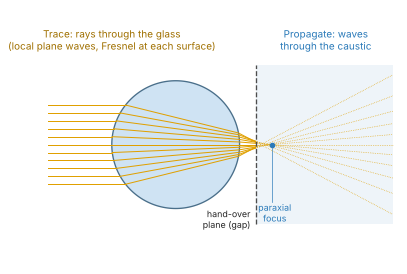

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.2))
sketch.ball_lens_handover(ax)
plt.show()

Inside the glass, rays are an excellent model: the surfaces are a hundred
wavelengths across, and locally the field looks like a plane wave meeting
a plane interface. `Trace(system)` does exactly that. It starts one ray at
every sample of the field, in the direction of the local wave vector (the
gradient of the phase), traces it through the real surfaces of a
`raytrace.System`, applies the Fresnel transmission coefficients for s and p
polarization at every surface, and rebuilds the field at the output plane
from where the rays arrive. The amplitude follows from energy
conservation: the power in a thin tube of neighbouring rays stays the same
(minus the Fresnel losses), so where the tube is squeezed the field gets
stronger.

Near the focus, rays fail. `Chain.from_system(system, gap=...)` therefore
stops the rays at a plane `gap` behind the last surface, before they
cross, and hands over to `Propagate`, which picks a wave optical method
for the rest of the way.

The reference is the exact solution of the (scalar) wave equation for a
sphere in this beam (`analytical.sphere_field`, a series of spherical
waves).

In [6]:
wl_b, a, n_b, w_b = 0.5, 50.0, 1.5, 25.0
flat = lambda r: np.exp(-(r/w_b)**6)                 # smooth flat top
x = np.linspace(-45, 45, 181)
X, Y = np.meshgrid(x, x)
src = ft.Field(flat(np.hypot(X, Y)), x, x, wl_b)
# the beam is defined in the plane of the sphere's centre: carry it back
# to the front vertex plane (z = -a) with the rigorous operator
front = ft.Chain([ft.Propagate(-a, method="spw")]).run(src).field

d = 25.0                                             # behind the back surface
ball = System([Surface(R=a, thickness=2*a, n_after=n_b, semi_diameter=0.999*a),
               Surface(R=-a, thickness=d, n_after=1.0, semi_diameter=0.999*a)], 0, wl_b)
x_focus = np.linspace(-10, 10, 201)
chain = ft.Chain.from_system(ball, gap=0.5) + [ft.Detector("focus", x=x_focus, y=x_focus)]
t0 = time.time()
res = chain.run(front)
print(res.report())
print("{:.1f} s".format(time.time() - t0))

  #  step                         method              error     samples pol.          ms  notes
  0  trace 2 surfaces             geometric (ray                181x181 scalar     378.1  
  1  propagate 24.5               spw               0.0e+00   4611x4611 scalar   14210.8  SPW reference not converged: errors are estimates
                                  candidates (error/effort): spw 0.0e+00/104019601, fresnel 5.2e-01/104019601, fresnel_ft 2.2e-01/32761, farfield 1.3e+00/33547264, geometric inf/inf
  2  detector 'focus'             detector                    4611x4611 scalar    7791.0  E_z carries 1.7e-02 of |E|^2: included
22.4 s


The report has one line per step: the method used, its estimated error,
the grid it ran on, whether the field was scalar or vectorial, and the
time. The trace takes well under a second. For the step into the focus,
through the caustic, only SPW meets the tolerance, on a large grid; the
detector looks at 20 × 20 µm around the focus. Along a radius of the focal
plane:

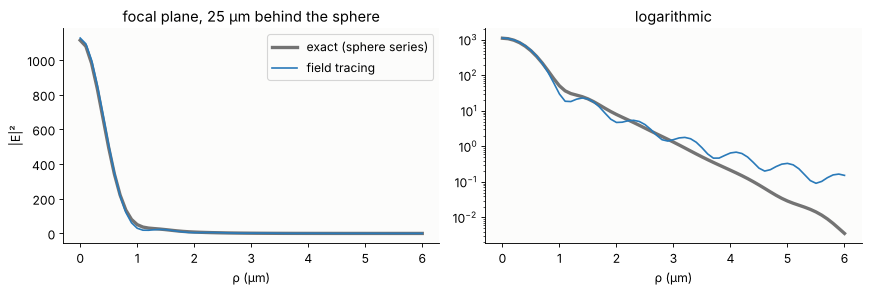

peak: field tracing 1127, exact 1115


In [7]:
# exact: the incident flat top as a sum of plane wave cones (Hankel transform)
r_q = np.linspace(0, 3*w_b, 3001)
k_rho = (np.arange(800) + 0.5)*0.004
A = (flat(r_q)*r_q) @ j0(np.outer(r_q, k_rho))*(r_q[1] - r_q[0])
rho = np.linspace(0, 6, 61)
u_exact = sphere_field(rho, a + d, a, n_b, wl_b, k_rho=k_rho, amplitudes=A*k_rho*0.004)

out = res["focus"].field
cut = out.resample(rho, np.array([-0.05, 0.0, 0.05]))
I_ft = np.abs(cut.E()[0][1])**2 + np.abs(cut.E()[1][1])**2

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(rho, np.abs(u_exact)**2, color=GREY, lw=3, label="exact (sphere series)")
ax[0].plot(rho, I_ft, color=BLUE, lw=1.5, label="field tracing")
ax[0].set_xlabel("ρ (µm)"); ax[0].set_ylabel("|E|²"); ax[0].legend()
ax[0].set_title("focal plane, {:.0f} µm behind the sphere".format(d))
ax[1].semilogy(rho, np.abs(u_exact)**2, color=GREY, lw=3)
ax[1].semilogy(rho, I_ft, color=BLUE, lw=1.5)
ax[1].set_xlabel("ρ (µm)"); ax[1].set_title("logarithmic")
plt.tight_layout(); plt.show()
print("peak: field tracing {:.0f}, exact {:.0f}".format(I_ft[0], np.abs(u_exact[0])**2))

Field tracing reproduces the aberrated focus: the peak within about 1 %,
the first ring and the shoulder within a few per cent. The remaining
differences are of the order of the tolerance and come from the rays: they
carry no diffraction from the rim of the beam and miss the weak light
reflected inside the sphere.

**Polarization.** The trace is vectorial. At a strongly curved surface, s
and p polarized light is transmitted differently, and the plane of
incidence turns around the axis. An x polarized beam therefore leaves the
sphere with a weak y polarized part in four lobes. With
`polarization="auto"` (the default) a chain measures that part after each
step and switches to a two-component field only when it exceeds the
tolerance; here it stays scalar, which halves the cost.

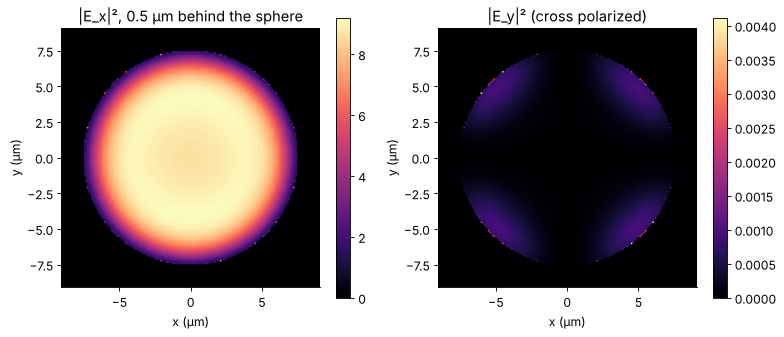

cross polarized share: 3.3e-05; power transmitted: 0.922 (two Fresnel losses: 0.922)


In [8]:
behind = ft.Chain([ft.Trace(System([Surface(R=a, thickness=2*a, n_after=n_b, semi_diameter=0.999*a),
                                    Surface(R=-a, thickness=0.5, n_after=1.0, semi_diameter=0.999*a)],
                                   0, wl_b))]).run(front, polarization="vector").field
Ex, Ey = behind.E()
ext = [behind.x[0], behind.x[-1], behind._y[0], behind._y[-1]]
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
im = ax[0].imshow(np.abs(Ex)**2, extent=ext, origin="lower", cmap="magma")
ax[0].set_title("|E_x|², 0.5 µm behind the sphere"); plt.colorbar(im, ax=ax[0])
im = ax[1].imshow(np.abs(Ey)**2, extent=ext, origin="lower", cmap="magma")
ax[1].set_title("|E_y|² (cross polarized)"); plt.colorbar(im, ax=ax[1])
for axx in ax: axx.set_xlabel("x (µm)"); axx.set_ylabel("y (µm)")
plt.tight_layout(); plt.show()
print("cross polarized share: {:.1e}; power transmitted: {:.3f} (two Fresnel losses: {:.3f})".format(
    np.sum(np.abs(Ey)**2)/np.sum(np.abs(Ex)**2 + np.abs(Ey)**2), behind.power()/front.power(),
    (1 - ((n_b - 1)/(n_b + 1))**2)**2))

## 5. A Mach-Zehnder interferometer with a small defect

An interferometer splits a beam into two arms and brings them together
again; the camera sees the interference of both. Here a plane wave of
8 × 8 mm at 800 nm is split into a reference arm with a 2 mm glass plate
and a test arm with a weak plano-convex lens (radius of curvature 1 m,
2 mm thick). The lens carries a small defect of 50 to 300 µm, an opaque
particle on its back surface. (The setup follows a use case published by
LightTrans for their VirtualLab software; it does not give the distances,
so we take 50 mm between the elements.)

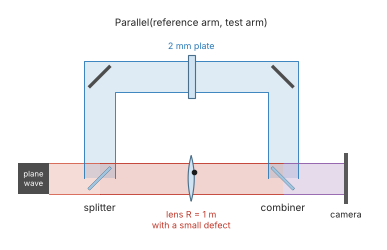

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.8))
sketch.mach_zehnder_defect(ax)
plt.show()

Two new pieces of a chain are needed:

* **Parallel arms.** `ft.Parallel(reference_arm, test_arm, weights=...)`
  runs the incoming field through each arm (each a list of steps) and
  keeps the results side by side. The weights are the amplitude factors of
  the splitters: two 50/50 splitters each pass $1/\sqrt2$ of the
  amplitude, so each arm reaches the camera with $1/2$.
* **The defect.** The beam is 8 mm wide and smooth, the defect a fraction
  of a millimetre: on one common grid, the whole beam would have to be
  sampled finely enough for the defect. Babinet's principle avoids that.
  The field behind the defect is the unobstructed field *minus* the small
  piece of field that the defect blocks:

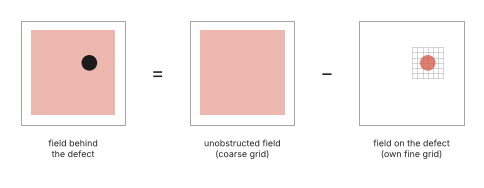

In [10]:
fig, ax = plt.subplots(figsize=(10, 2.8))
sketch.babinet_split(ax)
plt.show()

$$E_\mathrm{behind} = E\,(1 - M) = E - E\,M,$$

with $M$ = 1 on the defect and 0 elsewhere. `ft.Obstruction` creates
exactly these two parts: the unobstructed beam on its coarse grid, and the
small piece $-E\,M$ on its own fine grid around the defect. From then on
the chain carries both parts (a `FieldSum`), and each part is propagated
on its own grid with its own automatically chosen method. Because the
small part is weak, its error only counts relative to the whole field. All
parts are added coherently only at the detector.

The plate and the lens are traced through their real surfaces, with
Fresnel losses. The source has soft edges (0.1 mm wide), as real
collimated beams do.

In [11]:
wl_m, n_g, R_l, T_p, L = 0.0008, 1.5, 1000.0, 2.0, 50.0       # mm
edge = lambda u: 0.5*(1 - erf((np.abs(u) - 4.0)/0.1))
square = lambda X, Y: edge(X)*edge(Y)

x = np.linspace(-5, 5, 513)
X, Y = np.meshgrid(x, x)
source = ft.Field(square(X, Y), x, x, wl_m)
plate = System([Surface(thickness=T_p, n_after=n_g, semi_diameter=6.0),
                Surface(thickness=0.0, n_after=1.0, semi_diameter=6.0)], 0, wl_m)
lens = System([Surface(R=R_l, thickness=T_p, n_after=n_g, semi_diameter=6.0),
               Surface(thickness=0.0, n_after=1.0, semi_diameter=6.0)], 0, wl_m)
x_cam = np.linspace(-5, 5, 1001)
center = (1.0, 0.5)

def interferometer(radius):
    return ft.Chain([
        ft.Parallel([ft.Propagate(L), ft.Trace(plate), ft.Propagate(L)],
                    [ft.Propagate(L), ft.Trace(lens),
                     ft.Obstruction(radius=radius, center=center), ft.Propagate(L)],
                    weights=(0.5, 0.5)),
        ft.Propagate(L),
        ft.Detector("camera", x=x_cam, y=x_cam)])

t0 = time.time()
res = interferometer(0.1).run(source)
t_ft = time.time() - t0
print(res.report())
print("field tracing: {:.1f} s".format(t_ft))

  #  step                         method              error     samples pol.          ms  notes
0.1.0  propagate 50                 spw               0.0e+00     513x513 scalar     407.1  
                                  candidates (error/effort): spw 0.0e+00/263169, fresnel 5.0e-08/263169, fresnel_ft 1.8e-06/263169, farfield 2.2e+00/263169, geometric 3.0e-02/263169
0.1.1  trace 2 surfaces             geometric (ray                513x513 scalar     576.6  
0.1.2  propagate 50                 spw               0.0e+00     513x513 scalar     369.6  
                                  candidates (error/effort): spw 0.0e+00/263169, fresnel 2.8e-06/263169, fresnel_ft 7.2e-05/263169, farfield 2.2e+00/263169, geometric 1.9e-02/263169
0.2.0  propagate 50                 spw               0.0e+00     513x513 scalar     331.6  
                                  candidates (error/effort): spw 0.0e+00/263169, fresnel 5.0e-08/263169, fresnel_ft 1.8e-06/263169, farfield 2.2e+00/263169, geometric 3

In the report, steps 0.1.x are the reference arm and 0.2.x the test arm.
After the obstruction (0.2.2) there are two parts: the beam on 513 × 513
samples and the 200 µm defect on 31 × 31 samples, which its propagation
spreads over the 10 mm of the beam on only about 60 × 60 samples. Behind
the combiner the chain carries three parts (two beams and the defect) to
the camera.

To check the result, the same interferometer is simulated the brute-force
way: one grid of 4096 × 4096 samples over 12 mm (2.9 µm spacing, fine
enough for the defect everywhere), the angular spectrum method for every
free-space step, the lenses as thin phase plates with the same Fresnel
losses, and the defect as a hard disk.

brute force: 7.7 s, field tracing: 4.3 s
relative L2 difference of the interferograms: 9.9e-03


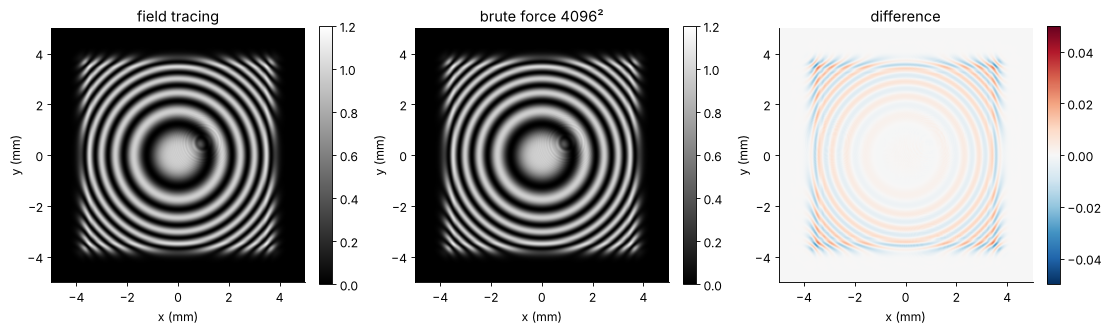

In [12]:
def brute_force(radius, N=4096, half=6.0):
    xb = np.linspace(-half, half, N)
    XB, YB = np.meshgrid(xb, xb)
    k = 2*np.pi/wl_m
    P = lambda u, z: rayleigh_sommerfeld_I_TF(u, xb, xb, z, wl_m)[0]
    t = 1 - ((n_g - 1)/(n_g + 1))**2                 # two surfaces: amplitude t
    u1 = P(square(XB, YB).astype(complex), L)
    ref = P(u1*t*np.exp(1j*k*n_g*T_p), L)
    h = T_p - (R_l - np.sqrt(R_l**2 - XB**2 - YB**2))   # glass thickness of the lens
    defect = ((XB - center[0])**2 + (YB - center[1])**2) > radius**2
    test = P(u1*t*np.exp(1j*k*(n_g*h + (T_p - h)))*defect, L)
    del u1
    u = P(0.5*(ref + test), L)
    pts = np.stack(np.meshgrid(x_cam, x_cam, indexing="ij"), -1)
    return RegularGridInterpolator((xb, xb), np.abs(u)**2)(pts)

t0 = time.time()
I_bf = brute_force(0.1)
t_bf = time.time() - t0
I_ft = res["camera"].irradiance
print("brute force: {:.1f} s, field tracing: {:.1f} s".format(t_bf, t_ft))
print("relative L2 difference of the interferograms: {:.1e}".format(
    np.linalg.norm(I_ft - I_bf)/np.linalg.norm(I_bf)))

ext = [x_cam[0], x_cam[-1]]*2
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
for axx, I, title in zip(ax, (I_ft, I_bf, I_ft - I_bf),
                         ("field tracing", "brute force 4096²", "difference")):
    kw = dict(cmap="RdBu_r", vmin=-0.05, vmax=0.05) if title == "difference" else dict(cmap="gray", vmin=0, vmax=1.2)
    im = axx.imshow(I, extent=ext, origin="lower", **kw)
    axx.set_title(title); axx.set_xlabel("x (mm)"); axx.set_ylabel("y (mm)")
    plt.colorbar(im, ax=axx, fraction=0.046)
plt.tight_layout(); plt.show()

The interferograms agree to about 1 % (the tolerance of the chain), at
roughly half the run time of the brute-force grid, which also needs about
2 GB of memory. More importantly, the cost of field tracing does not grow
when the defect shrinks: the defect always gets 31 samples across, while a
single grid must resolve the smallest feature over the whole beam.

The rings are Newton's rings: the lens (focal length R/(n − 1) = 2 m) turns
the test beam into a slowly converging spherical wave, which interferes
with the plane reference wave. The defect at (1, 0.5) mm casts its
diffraction pattern into them. Defects of 50 to 300 µm:

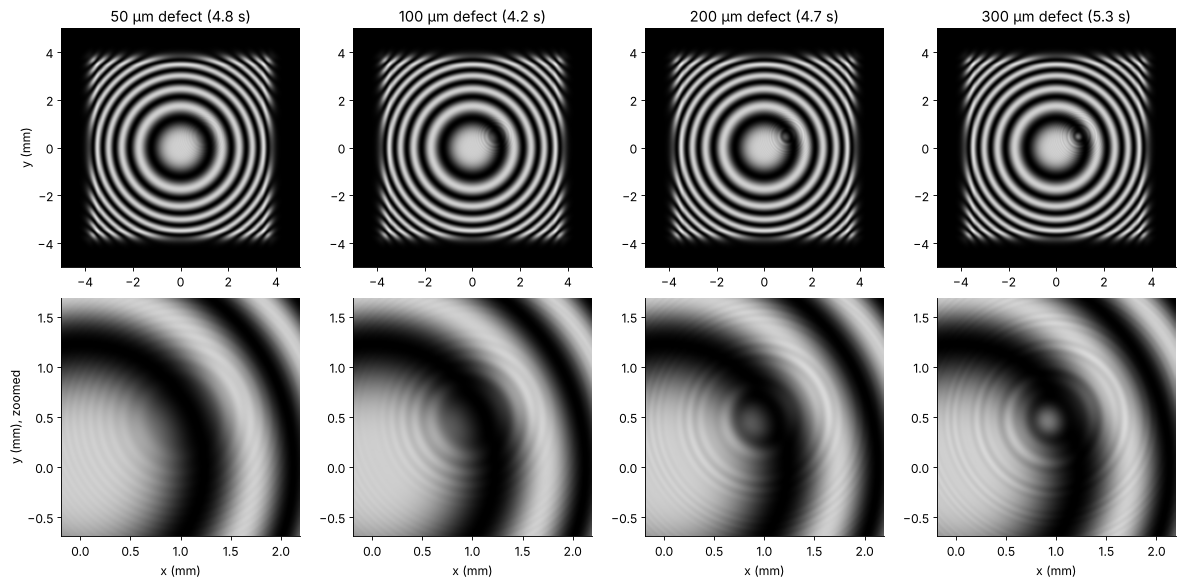

In [13]:
fig, ax = plt.subplots(2, 4, figsize=(15, 7.4))
zoom = (np.abs(x_cam - center[0]) < 1.2)
zoom_y = (np.abs(x_cam - center[1]) < 1.2)
for j, diameter in enumerate((0.05, 0.1, 0.2, 0.3)):
    t0 = time.time()
    r = interferometer(diameter/2).run(source)
    I = r["camera"].irradiance
    ax[0, j].imshow(I, extent=ext, origin="lower", cmap="gray", vmin=0, vmax=1.2)
    ax[0, j].set_title("{:.0f} µm defect ({:.1f} s)".format(diameter*1E3, time.time() - t0))
    ax[1, j].imshow(I[np.ix_(zoom_y, zoom)], origin="lower", cmap="gray", vmin=0, vmax=1.2,
                    extent=[x_cam[zoom][0], x_cam[zoom][-1], x_cam[zoom_y][0], x_cam[zoom_y][-1]])
    ax[1, j].set_xlabel("x (mm)")
ax[0, 0].set_ylabel("y (mm)"); ax[1, 0].set_ylabel("y (mm), zoomed")
plt.tight_layout(); plt.show()

The smallest defect only adds a faint ring system; the larger ones cast a
dark shadow with a bright spot in its centre (the Arago spot) and shift
the Newton's rings locally.

## Summary

* Field tracing carries the field through a system as a product of
  operators, one per component and free-space step. In
  `pyoptics.fieldtrace` that product is a list (`Chain`), and the run
  reports, step by step, what was done, how accurately and at what cost.
* Each free-space step chooses its method (spectrum of plane waves,
  Fresnel, far field, geometrical optics) by comparing error and effort on
  cuts of the field.
* `Trace(system)` and `Chain.from_system(system, gap=...)` take the field
  through real lens surfaces with rays, including polarization and Fresnel
  losses, and hand over to waves where diffraction matters; the ball lens
  focus agrees with the exact solution within the 1 % tolerance.
* `Parallel` arms and `Obstruction` (Babinet) parts keep fields with very
  different sizes on their own grids; the interferogram with a 200 µm
  defect matches a 4096² brute-force simulation within 1 %.

Reference: F. Wyrowski and M. Kuhn, "Introduction to field tracing",
J. Mod. Opt. 58, 449–466 (2011).

In [14]:
print("total run time: {:.0f} s".format(time.time() - t_start))

total run time: 58 s
